# 02 - Anomaly detection (Isolation Forest)

**Question:** *do the sensors look like a healthy machine?*

This model needs **no failure labels**: it learns what "normal" looks like from tools in good condition
(wear < 0.2 mm), then flags anything that looks different.
It only looks at the sensors (relative to the new tool), not at the cutting time. In real plants this is often the first model
deployed, because failures are rare and labels are expensive.

In [1]:
import sys, json
sys.path.append("..")  # to import features.py from the project root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from features import FEATURES, SIGNAL_FEATURES, WEAR_LIMIT_MM

In [2]:
df = pd.read_csv("../data/milling_features.csv")
print(len(df), "runs from", df["case"].nunique(), "tools")

166 runs from 16 tools


In [3]:
from sklearn.ensemble import IsolationForest

healthy = df[df["wear_mm"] < 0.2]
print("Training on", len(healthy), "healthy runs")

model = IsolationForest(n_estimators=200, random_state=42)
model.fit(healthy[SIGNAL_FEATURES])

Training on 50 healthy runs


,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


## Anomaly score and threshold

`score_samples` is high for normal points, so we flip the sign: **higher score = more abnormal**.
The alarm threshold is the 95th percentile of the healthy scores (5% false alarm rate on healthy data).

In [4]:
df["anomaly_score"] = -model.score_samples(df[SIGNAL_FEATURES])
threshold = float(np.percentile(-model.score_samples(healthy[SIGNAL_FEATURES]), 95))
print("Threshold:", round(threshold, 3))

Threshold: 0.567


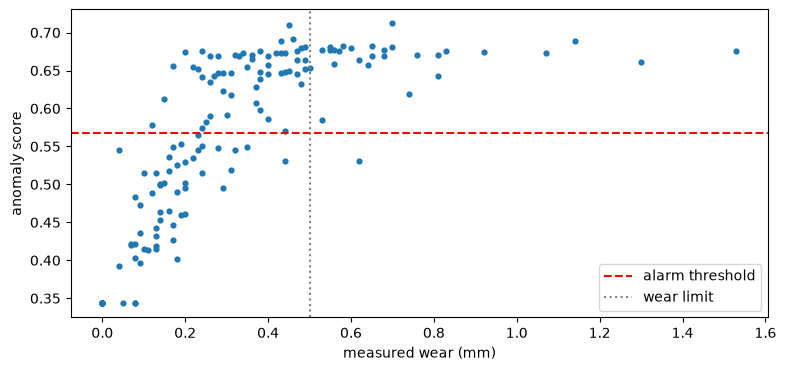

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(df["wear_mm"], df["anomaly_score"], s=12)
ax.axhline(threshold, color="red", ls="--", label="alarm threshold")
ax.axvline(WEAR_LIMIT_MM, color="grey", ls=":", label="wear limit")
ax.set_xlabel("measured wear (mm)"); ax.set_ylabel("anomaly score"); ax.legend();

## How often does it alarm?

In [6]:
bins = pd.cut(df["wear_mm"], [-0.01, 0.2, 0.35, 0.5, 2], labels=["< 0.2", "0.2-0.35", "0.35-0.5", "> 0.5 (worn)"])
alarm_rate = (df["anomaly_score"] > threshold).groupby(bins, observed=True).mean()
alarm_rate.round(2).rename("alarm rate").to_frame()

,alarm rate
wear_mm,
< 0.2,0.07
0.2-0.35,0.68
0.35-0.5,0.97
> 0.5 (worn),0.96


## Save

In [7]:
worn = df["wear_mm"] >= WEAR_LIMIT_MM
metrics = {
    "name": "Isolation Forest",
    "task": "Anomaly detection (no labels)",
    "threshold": round(threshold, 4),
    "score": f"alarms on {(df.loc[worn, 'anomaly_score'] > threshold).mean():.0%} of worn-tool runs",
}
joblib.dump(model, "../models/anomaly_detector.joblib")
json.dump(metrics, open("../models/anomaly_detector_metrics.json", "w"), indent=2)
metrics

{'name': 'Isolation Forest',
 'task': 'Anomaly detection (no labels)',
 'threshold': 0.5673,
 'score': 'alarms on 97% of worn-tool runs'}